In [1]:
!git clone https://github.com/Thinh-MaNU/Machine-learning-project-.git
%cd Machine-learning-project-

Cloning into 'Machine-learning-project-'...
remote: Enumerating objects: 112, done.
remote: Counting objects: 100% (112/112), done.
remote: Compressing objects: 100% (82/82), done.
remote: Total 112 (delta 44), reused 81 (delta 26), pack-reused 0 (from 0)
Receiving objects: 100% (112/112), 68.56 KiB | 3.43 MiB/s, done.
Resolving deltas: 100% (44/44), done.
/content/Machine-learning-project-


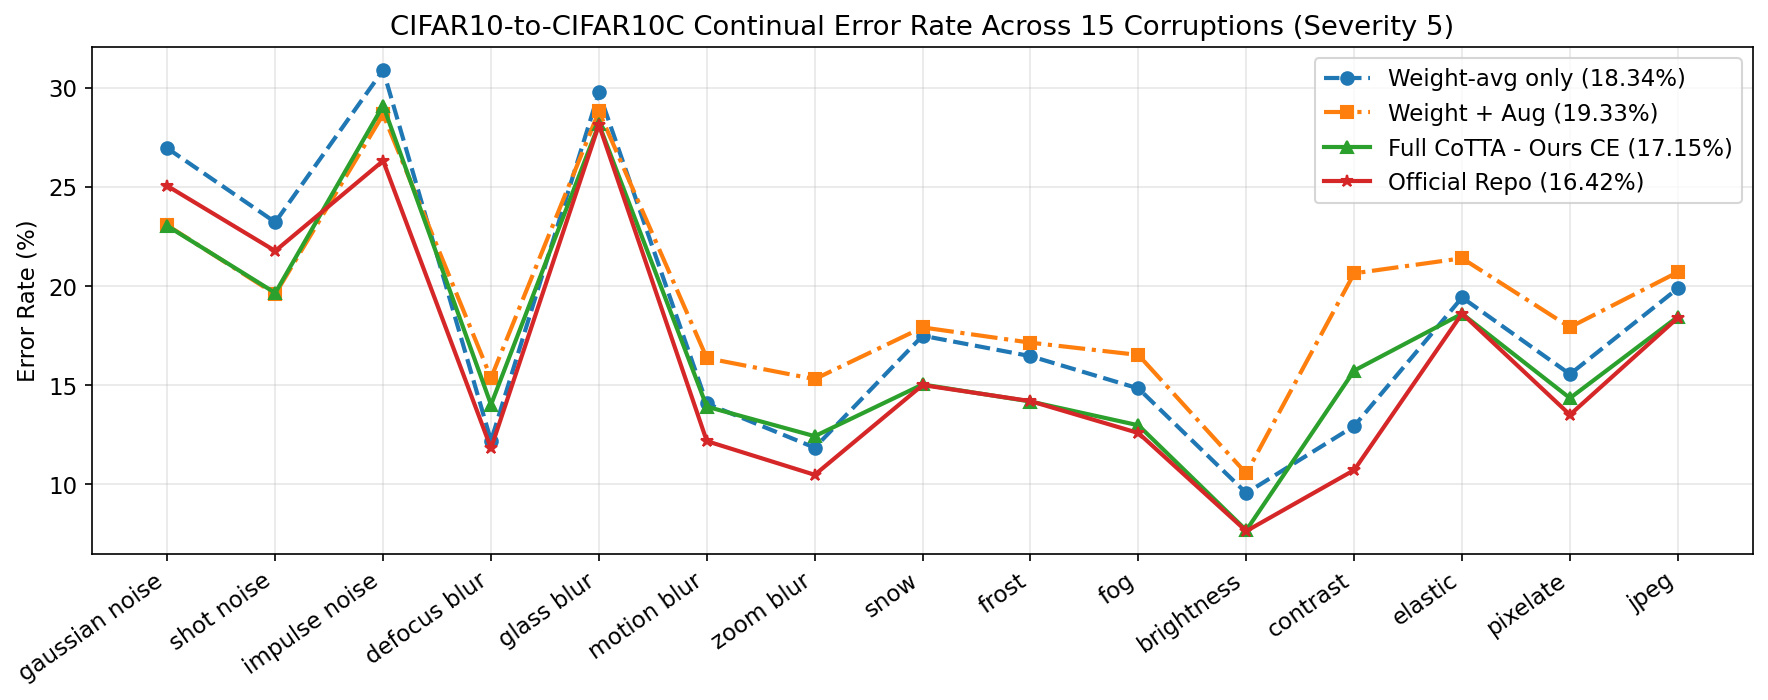

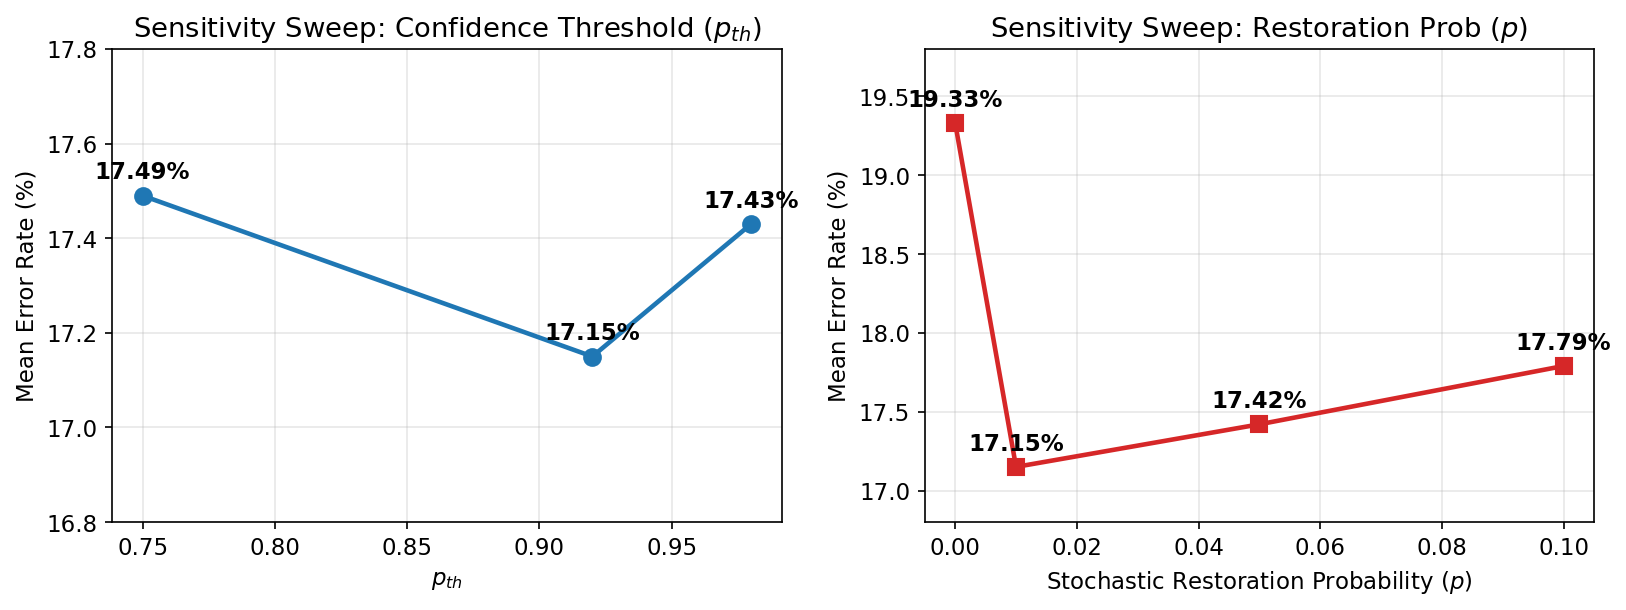

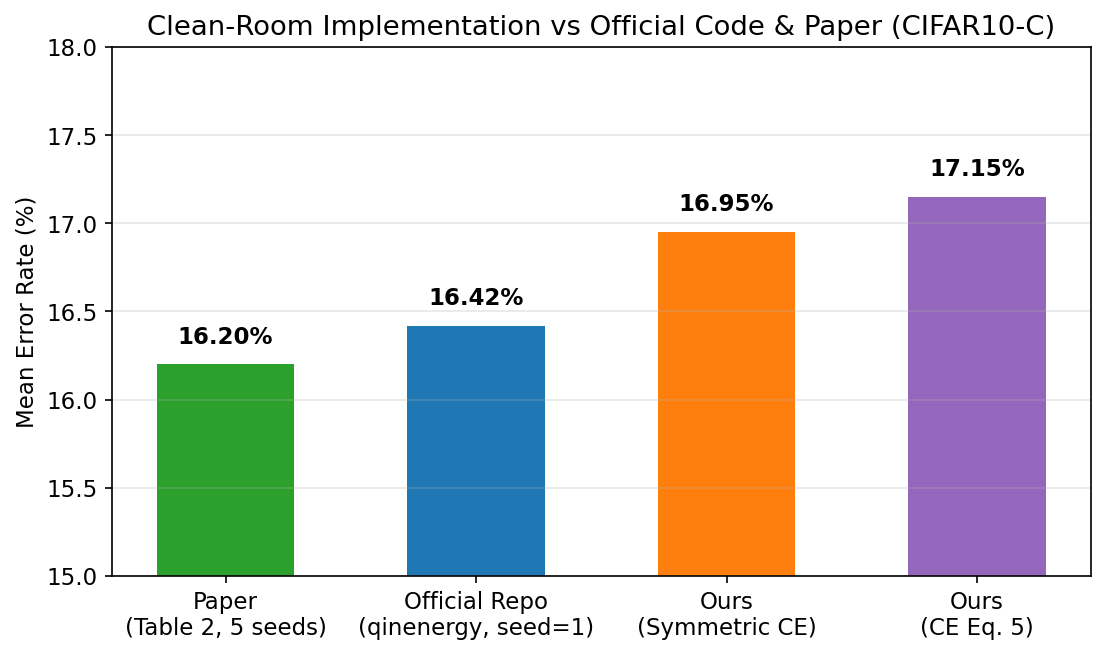

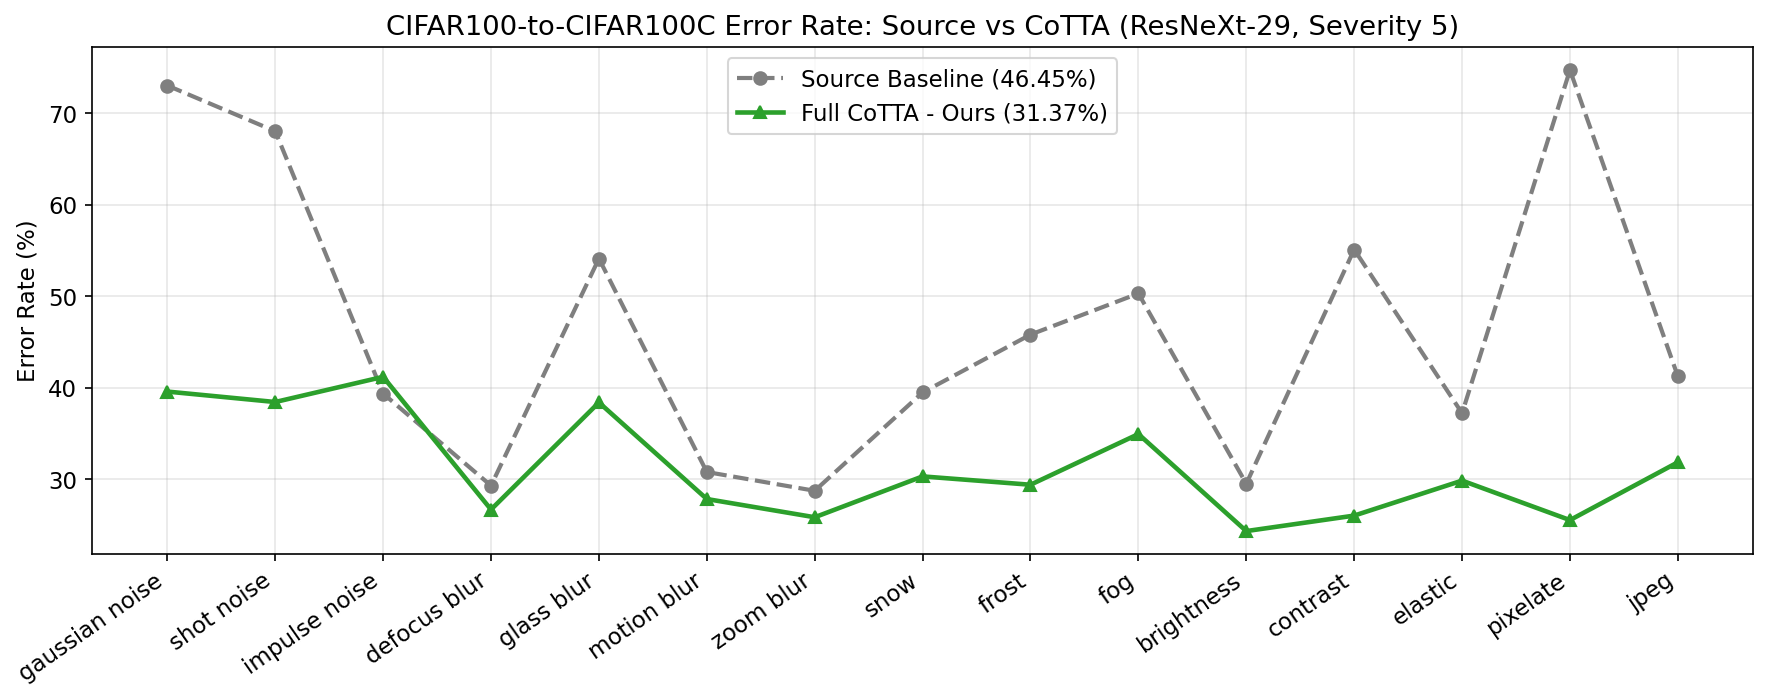

In [2]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

Path("outputs/figures").mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 11, "figure.dpi": 150})

with open("outputs/reproduce_cifar10c_ce.json") as f: c10 = json.load(f)
with open("outputs/reproduce_cifar100c_ce.json") as f: c100 = json.load(f)
with open("outputs/sensitivity_p_th.json") as f: s_pth = json.load(f)
with open("outputs/sensitivity_restore_p.json") as f: s_rst = json.load(f)
with open("outputs/compare_original_summary.json") as f: cmp = json.load(f)

corrs = list(c100["per_corruption"].keys())
short_corrs = [c.replace("_transform", "").replace("_compression", "").replace("_blur", " blur").replace("_noise", " noise") for c in corrs]
x = np.arange(len(corrs))

# 1. Biểu đồ CIFAR10-C qua 15 corruptions (Ablation + Official Repo)
plt.figure(figsize=(12, 4.8))
for label, d, style in [
    ("Weight-avg only (18.34%)", c10["weight_avg_only"]["runs"][0], "--o"),
    ("Weight + Aug (19.33%)", c10["weight_and_aug"]["runs"][0], "-.s"),
    ("Full CoTTA - Ours CE (17.15%)", c10["full_cotta"]["runs"][0], "-^"),
    ("Official Repo (16.42%)", cmp["official_repo_run"]["per_corruption"], "-*"),
]:
    y = [d[k] for k in corrs]
    plt.plot(x, y, style, label=label, linewidth=2, markersize=6)
plt.xticks(x, short_corrs, rotation=35, ha="right")
plt.ylabel("Error Rate (%)")
plt.title("CIFAR10-to-CIFAR10C Continual Error Rate Across 15 Corruptions (Severity 5)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("outputs/figures/fig1_cifar10c_ablation.png", dpi=300)
plt.show()

# 2. Biểu đồ Sensitivity Sweep (2 đường cong chữ U: p_th và restore_p)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
pth_vals = [item["value"] for item in s_pth]
pth_errs = [item["mean_error"] for item in s_pth]
axes[0].plot(pth_vals, pth_errs, "-o", color="#1f77b4", linewidth=2.2, markersize=8)
for vx, vy in zip(pth_vals, pth_errs):
    axes[0].annotate(f"{vy:.2f}%", (vx, vy), textcoords="offset points", xytext=(0, 8), ha="center", fontweight="bold")
axes[0].set_title("Sensitivity Sweep: Confidence Threshold ($p_{th}$)")
axes[0].set_xlabel("$p_{th}$")
axes[0].set_ylabel("Mean Error Rate (%)")
axes[0].set_ylim(16.8, 17.8)
axes[0].grid(alpha=0.3)

rst_vals = [item["value"] for item in s_rst]
rst_errs = [item["mean_error"] for item in s_rst]
axes[1].plot(rst_vals, rst_errs, "-s", color="#d62728", linewidth=2.2, markersize=8)
for vx, vy in zip(rst_vals, rst_errs):
    axes[1].annotate(f"{vy:.2f}%", (vx, vy), textcoords="offset points", xytext=(0, 8), ha="center", fontweight="bold")
axes[1].set_title("Sensitivity Sweep: Restoration Prob ($p$)")
axes[1].set_xlabel("Stochastic Restoration Probability ($p$)")
axes[1].set_ylabel("Mean Error Rate (%)")
axes[1].set_ylim(16.8, 19.8)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/figures/fig2_sensitivity_sweeps.png", dpi=300)
plt.show()

# 3. Biểu đồ cột Original-Code Comparison
labels = ["Paper\n(Table 2, 5 seeds)", "Official Repo\n(qinenergy, seed=1)", "Ours\n(Symmetric CE)", "Ours\n(CE Eq. 5)"]
vals = [16.20, cmp["official_repo_run"]["mean_error"], cmp["ours_symmetric_ce_official_loss"]["mean_error"], cmp["ours_ce_paper_eq5"]["mean_error"]]
colors = ["#2ca02c", "#1f77b4", "#ff7f0e", "#9467bd"]
plt.figure(figsize=(7.5, 4.5))
bars = plt.bar(labels, vals, color=colors, width=0.55)
for b, v in zip(bars, vals):
    plt.text(b.get_x() + b.get_width()/2, v + 0.12, f"{v:.2f}%", ha="center", fontweight="bold")
plt.ylim(15.0, 18.0)
plt.ylabel("Mean Error Rate (%)")
plt.title("Clean-Room Implementation vs Official Code & Paper (CIFAR10-C)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/figures/fig3_original_comparison.png", dpi=300)
plt.show()

# 4. Biểu đồ CIFAR100-C: Source (46.45%) vs Full CoTTA (31.37%)
c100_source = [73.00, 68.01, 39.37, 29.32, 54.11, 30.81, 28.76, 39.49, 45.81, 50.30, 29.53, 55.10, 37.23, 74.69, 41.25]
c100_cotta = [c100["per_corruption"][k] for k in corrs]
plt.figure(figsize=(12, 4.8))
plt.plot(x, c100_source, "--o", color="#7f7f7f", label="Source Baseline (46.45%)", linewidth=2)
plt.plot(x, c100_cotta, "-^", color="#2ca02c", label="Full CoTTA - Ours (31.37%)", linewidth=2.2)
plt.xticks(x, short_corrs, rotation=35, ha="right")
plt.ylabel("Error Rate (%)")
plt.title("CIFAR100-to-CIFAR100C Error Rate: Source vs CoTTA (ResNeXt-29, Severity 5)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("outputs/figures/fig4_cifar100c_source_vs_cotta.png", dpi=300)
plt.show()